<a href="https://colab.research.google.com/github/gayatridixit1713-droid/EDA-project/blob/main/EDA_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Step 1:Setup and First Look

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Set plotting style and default figure size
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Read CSV file
try:
    df = pd.read_csv("train.csv")
except FileNotFoundError:
    # Creating a dummy dataframe for demonstration if train.csv doesn't exist
    print("Warning: 'train.csv' not found. Creating dummy data for demonstration.")
    df = pd.DataFrame({
        'A': [1, 2, np.nan, 4, 5],
        'B': [np.nan, 2, 3, np.nan, 5],
        'C': [1, 2, 3, 4, 5]
    })

# Print shape of df
print(f"Shape of dataframe: {df.shape}\n")

# Print first 5 rows
print("First 5 rows:")
print(df.head())
print("\n" + "="*50 + "\n")

# Print info
print("Dataframe Info:")
df.info()
print("\n" + "="*50 + "\n")

# Count null values per column and sort descending
missing = df.isnull().sum()
missing_sorted = missing.sort_values(ascending=False)

# Print columns where missing > 0 with percentage
print("Columns with missing values and their percentage:")
missing_cols = missing_sorted[missing_sorted > 0]
if not missing_cols.empty:
    for col, count in missing_cols.items():
        percentage = (count / len(df)) * 100
        print(f"{col}: {count} missing values ({percentage:.2f}%)")
else:
    print("No missing values found.")

Shape of dataframe: (1460, 81)

First 5 rows:
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSold  SaleType  Sa

Step 2 :Classify V ariables

In [4]:
import pandas as pd

# Identify numeric and categorical columns
numeric_cols = df.select_dtypes(include=['number']).columns.tolist()
categorical_cols = df.select_dtypes(exclude=['number']).columns.tolist()

# Define the ordinal map with correct string values
ordinal_map = {
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"]
}

# Convert mapped columns to ordered Categorical
for col, categories in ordinal_map.items():
    if col in df.columns:
        df[col] = pd.Categorical(df[col], categories=categories, ordered=True)

# Build a summary table
summary_data = []
for col in df.columns:
    col_type = str(df[col].dtype)
    num_unique = df[col].nunique(dropna=False)

    # Get a list of unique example values (excluding nulls for readability, up to 3 examples)
    examples = df[col].dropna().unique()[:3].tolist()
    example_str = ", ".join(map(str, examples))

    summary_data.append({
        "column_name": col,
        "type": col_type,
        "number of unique values": num_unique,
        "example values": example_str
    })

summary_df = pd.DataFrame(summary_data)

# Display the summary table
import IPython.display as display
display.display(summary_df)

,column_name,type,number of unique values,example values
0,Id,int64,1460,"1, 2, 3"
1,MSSubClass,int64,15,"60, 20, 70"
2,MSZoning,object,5,"RL, RM, C (all)"
3,LotFrontage,float64,111,"65.0, 80.0, 68.0"
4,LotArea,int64,1073,"8450, 9600, 11250"
...,...,...,...,...
76,MoSold,int64,12,"2, 5, 9"
77,YrSold,int64,5,"2008, 2007, 2006"
78,SaleType,object,9,"WD, New, COD"
79,SaleCondition,object,6,"Normal, Abnorml, Partial"


Step 3:  Descriptive Statistics

In [20]:
import pandas as pd
import numpy as np

# Display describe() for numeric columns
print("Descriptive Statistics for All Numeric Columns:")
display(df.describe())
print("\n" + "="*80 + "\n")

# Detailed descriptive statistics for selected columns
target_columns = [col for col in ['SalePrice', 'GrLivArea', 'LotArea'] if col in df.columns]

for column in target_columns:
    col_data = df[column].dropna()

    # Calculate statistics
    mean_val = col_data.mean()
    median_val = col_data.median()

    # Mode might return multiple values, we take the first one if it exists
    mode_series = col_data.mode()
    mode_val = mode_series.iloc[0] if not mode_series.empty else np.nan

    std_val = col_data.std()
    var_val = col_data.var()
    range_val = col_data.max() - col_data.min()

    q1 = col_data.quantile(0.25)
    q3 = col_data.quantile(0.75)
    iqr_val = q3 - q1

    skew_val = col_data.skew()
    kurt_val = col_data.kurt()

    # Print all values
    print(f"--- Statistics for {column} ---")
    print(f"Mean:               {mean_val:.2f}")
    print(f"Median:             {median_val:.2f}")
    print(f"Mode:               {mode_val:.2f}")
    print(f"Std Dev:            {std_val:.2f}")
    print(f"Variance:           {var_val:.2f}")
    print(f"Range:              {range_val:.2f}")
    print(f"IQR:                {iqr_val:.2f}")
    print(f"Skewness:           {skew_val:.4f}")
    print(f"Kurtosis:           {kurt_val:.4f}")

    # Determine skewness note
    if mean_val > median_val:
        print("Note: Right skewed (positive skew)")
    elif mean_val < median_val:
        print("Note: Left skewed (negative skew)")
    else:
        print("Note: Symmetric distribution")
    print("\n")

Descriptive Statistics for All Numeric Columns:


TypeError: 'module' object is not callable

Step 4: Distributions

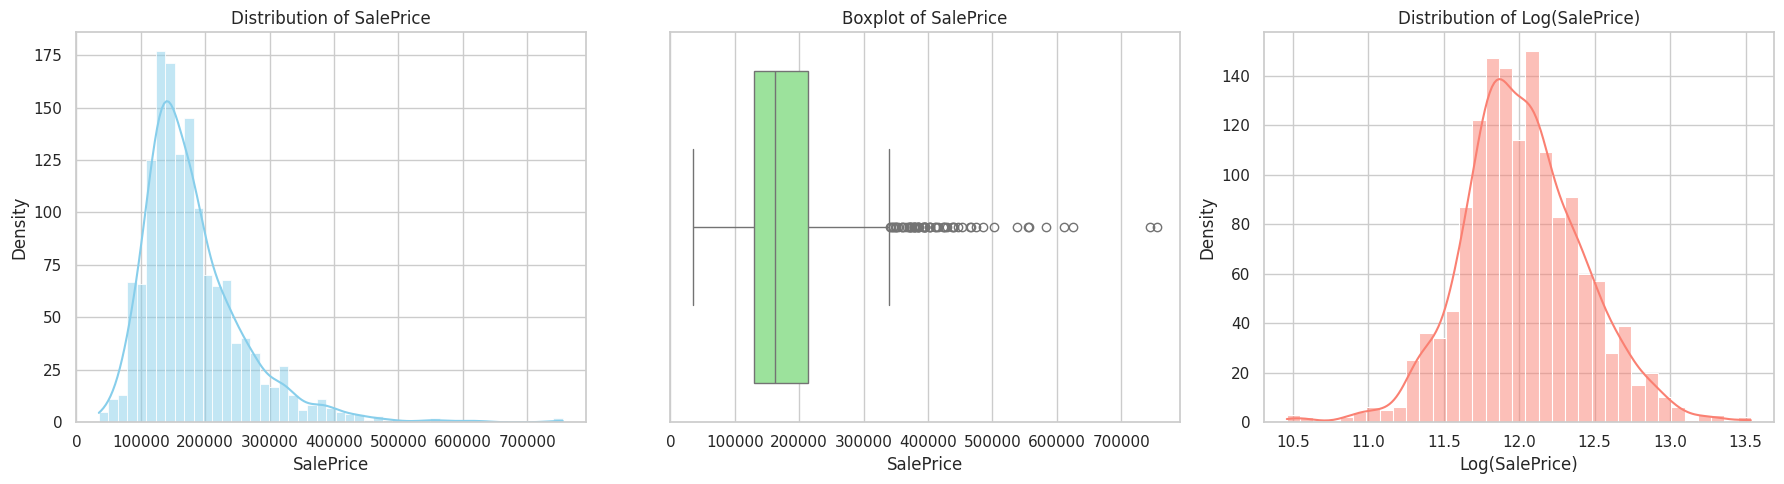

Skewness of SalePrice: 1.8813
Skewness of Log(SalePrice): 0.1216



/tmp/ipykernel_822/1018539830.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='OverallQual', y='SalePrice', palette='coolwarm')


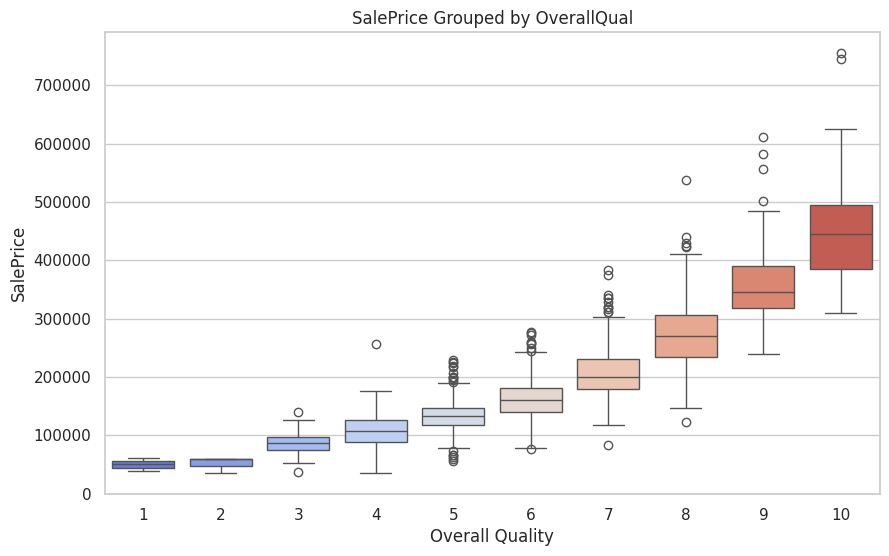

/tmp/ipykernel_822/1018539830.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Neighborhood', y='SalePrice', order=neighborhood_order, palette='viridis')


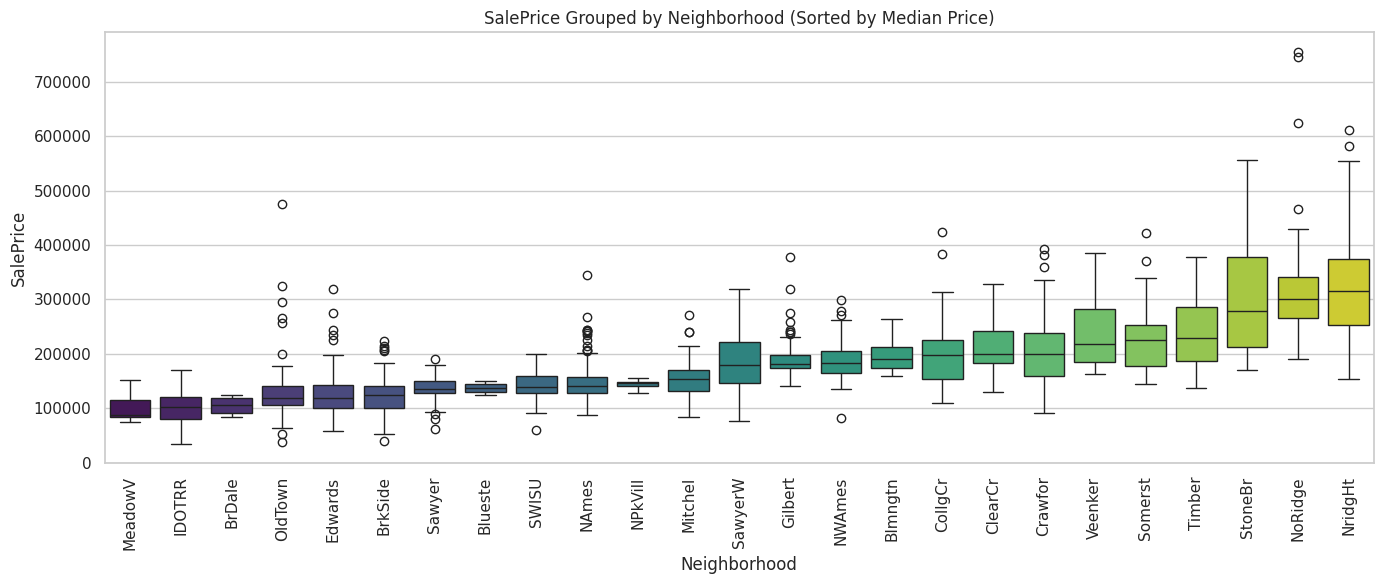

/tmp/ipykernel_822/1018539830.py:58: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='OverallQual', ax=axes[0], palette='Blues')
/tmp/ipykernel_822/1018539830.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='HouseStyle', ax=axes[1], palette='Oranges')


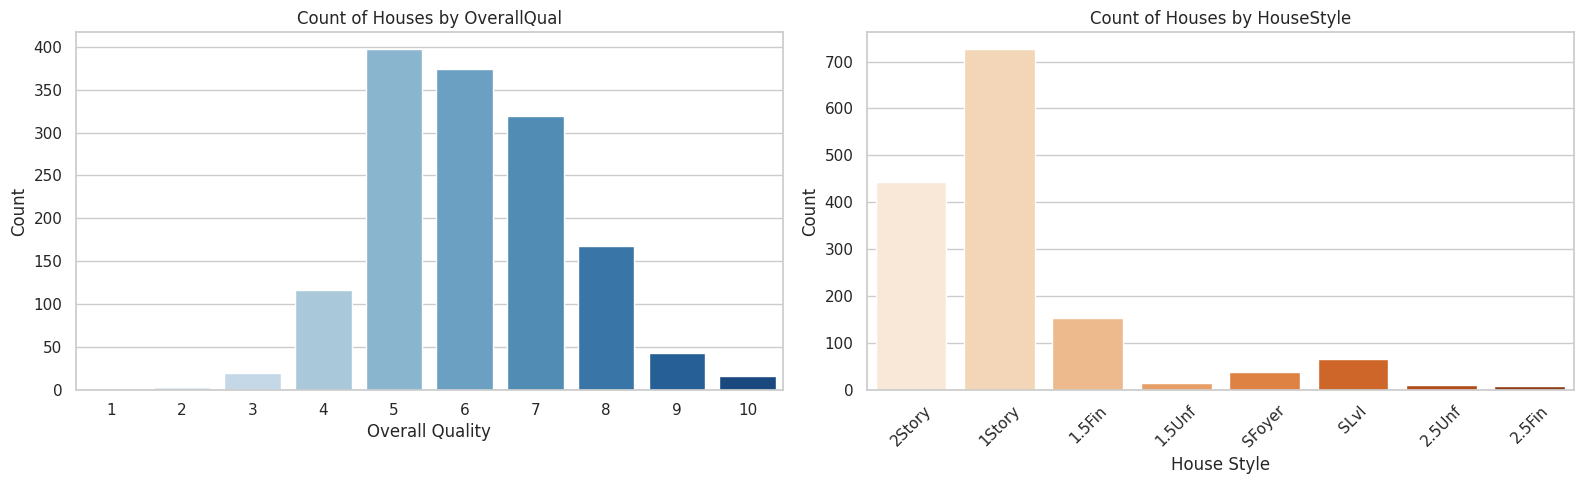

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. CREATE figure with 1 row, 3 columns
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Axis 1: HISTOGRAM of SalePrice with KDE overlay
sns.histplot(df['SalePrice'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of SalePrice')
axes[0].set_xlabel('SalePrice')
axes[0].set_ylabel('Density')

# Axis 2: BOXPLOT of SalePrice
sns.boxplot(x=df['SalePrice'], ax=axes[1], color='lightgreen')
axes[1].set_title('Boxplot of SalePrice')
axes[1].set_xlabel('SalePrice')

# Axis 3: HISTOGRAM of LOG(SalePrice)
log_saleprice = np.log1p(df['SalePrice'])
sns.histplot(log_saleprice, kde=True, ax=axes[2], color='salmon')
axes[2].set_title('Distribution of Log(SalePrice)')
axes[2].set_xlabel('Log(SalePrice)')
axes[2].set_ylabel('Density')

plt.tight_layout()
plt.show()

# COMPARE skewness before and after log
skew_before = df['SalePrice'].skew()
skew_after = log_saleprice.skew()
print(f"Skewness of SalePrice: {skew_before:.4f}")
print(f"Skewness of Log(SalePrice): {skew_after:.4f}\n")

# 2. CREATE figure with boxplot of SalePrice grouped by OverallQual
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='OverallQual', y='SalePrice', palette='coolwarm')
plt.title('SalePrice Grouped by OverallQual')
plt.xlabel('Overall Quality')
plt.ylabel('SalePrice')
plt.show()

# 3. CREATE figure with boxplot of SalePrice grouped by Neighborhood
plt.figure(figsize=(14, 6))
# SORT neighborhoods by median price
neighborhood_order = df.groupby('Neighborhood')['SalePrice'].median().sort_values().index
sns.boxplot(data=df, x='Neighborhood', y='SalePrice', order=neighborhood_order, palette='viridis')
plt.title('SalePrice Grouped by Neighborhood (Sorted by Median Price)')
plt.xlabel('Neighborhood')
plt.ylabel('SalePrice')
# ROTATE x labels 90 degrees
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# 4. CREATE countplots of OverallQual and HouseStyle
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.countplot(data=df, x='OverallQual', ax=axes[0], palette='Blues')
axes[0].set_title('Count of Houses by OverallQual')
axes[0].set_xlabel('Overall Quality')
axes[0].set_ylabel('Count')

sns.countplot(data=df, x='HouseStyle', ax=axes[1], palette='Oranges')
axes[1].set_title('Count of Houses by HouseStyle')
axes[1].set_xlabel('House Style')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Step 5: Correlation and Covariance

In [18]:
import pandas as pd
import numpy as np

# Filter only numeric columns for correlation and covariance
numeric_df = df.select_dtypes(include=[np.number])

# 1. Compute COVARIANCE and CORRELATION matrices
cov_matrix = numeric_df.cov()
corr_matrix = numeric_df.corr(method='pearson')

# 2. Find and SORT absolute correlation with SalePrice descending (excluding SalePrice itself)
if 'SalePrice' in corr_matrix.columns:
    saleprice_corr = corr_matrix['SalePrice'].drop('SalePrice')
    top_corr = saleprice_corr.abs().sort_values(ascending=False)

    # PRINT top 10 features and their correlation values (using actual signed correlation)
    print("--- Top 10 Features Correlated with SalePrice ---")
    top_10_features = top_corr.head(10).index
    for col in top_10_features:
        print(f"{col:15s}: Correlation = {corr_matrix.loc[col, 'SalePrice']:.4f}")
    print("\n" + "="*60 + "\n")

    # 3. FOR the top 3 features, PRINT covariance and correlation with SalePrice
    print("--- Comparison for Top 3 Features ---")
    top_3_features = top_corr.head(3).index
    for col in top_3_features:
        cov_val = cov_matrix.loc[col, 'SalePrice']
        corr_val = corr_matrix.loc[col, 'SalePrice']
        print(f"{col:15s}: Covariance = {cov_val:12.2f} | Correlation = {corr_val:.4f}")
    print("\n" + "="*60 + "\n")

# 4. EXPLAIN why correlation is easier to compare than covariance
explanation = """Why Correlation is easier to compare than Covariance:
1. Scale Interpretation: Covariance is unbounded and depends entirely on the units of the variables (e.g., square feet times dollars). This makes it impossible to determine strength of relationship from the covariance number alone.
2. Standardization: Correlation standardizes covariance by dividing it by the product of the standard deviations of the two variables, scaling it to a strict range between -1 and +1. This allows immediate, direct comparison across completely different variables."""
print(explanation)
print("\n" + "="*60 + "\n")

# 5. OPTIONAL: compute Spearman correlation for ordinal columns
ordinal_cols = [col for col in ["ExterQual", "KitchenQual"] if col in df.columns]
if ordinal_cols and 'SalePrice' in df.columns:
    print("--- Spearman Rank Correlation for Ordinal Columns with SalePrice ---")
    for col in ordinal_cols:
        # Map the ordered categories to numeric codes for correlation analysis
        encoded_col = df[col].cat.codes
        spearman_corr, _ = stats.spearmanr(encoded_col, df['SalePrice'], nan_policy='omit')
        print(f"{col:15s}: Spearman Correlation = {spearman_corr:.4f}")
else:
    print("Ordinal columns or SalePrice not available for Spearman correlation.")

--- Top 10 Features Correlated with SalePrice ---
OverallQual    : Correlation = 0.7958
GrLivArea      : Correlation = 0.7350
TotalBsmtSF    : Correlation = 0.6512
GarageCars     : Correlation = 0.6410
1stFlrSF       : Correlation = 0.6315
GarageArea     : Correlation = 0.6292
FullBath       : Correlation = 0.5622
TotRmsAbvGrd   : Correlation = 0.5378
YearBuilt      : Correlation = 0.5236
YearRemodAdd   : Correlation = 0.5077


--- Comparison for Top 3 Features ---
OverallQual    : Covariance =     87069.24 | Correlation = 0.7958
GrLivArea      : Covariance =  29673479.76 | Correlation = 0.7350
TotalBsmtSF    : Covariance =  21480911.02 | Correlation = 0.6512


Why Correlation is easier to compare than Covariance:
1. Scale Interpretation: Covariance is unbounded and depends entirely on the units of the variables (e.g., square feet times dollars). This makes it impossible to determine strength of relationship from the covariance number alone.
2. Standardization: Correlation standardizes

Step 6: Scatter Plots and Pair Plots

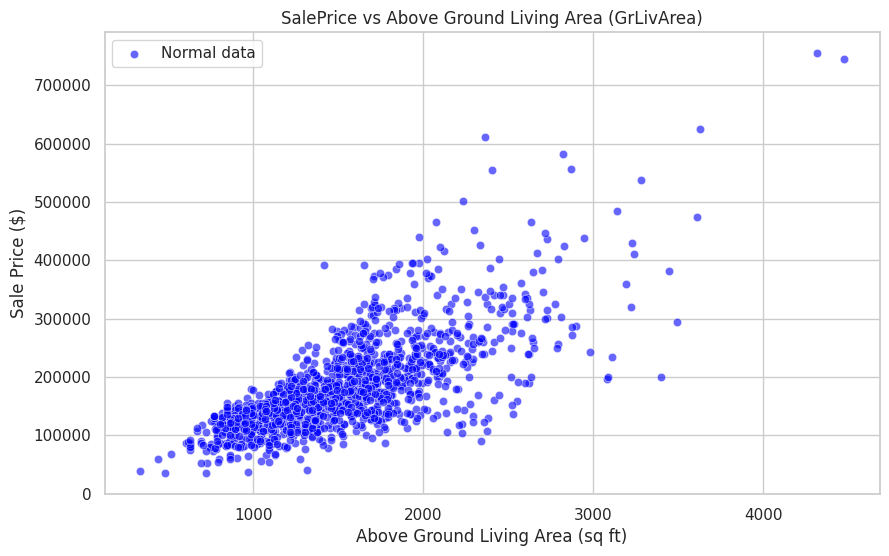

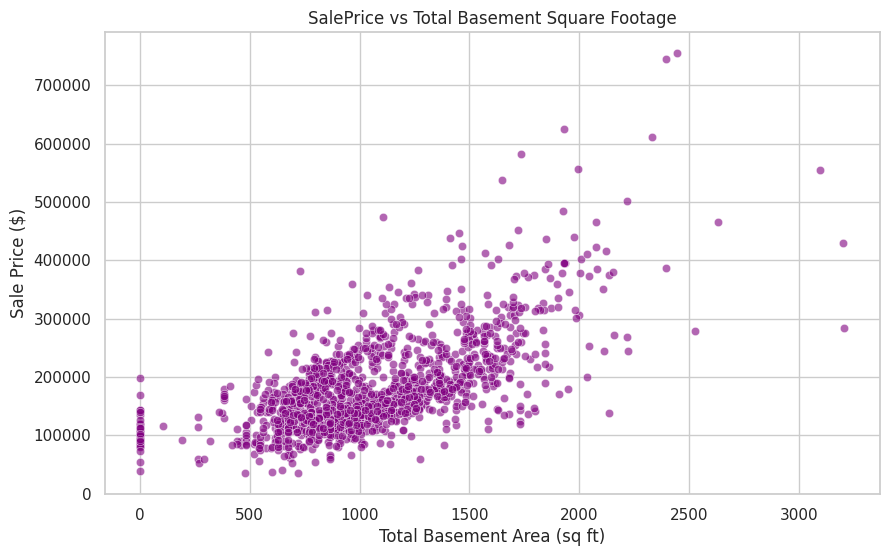

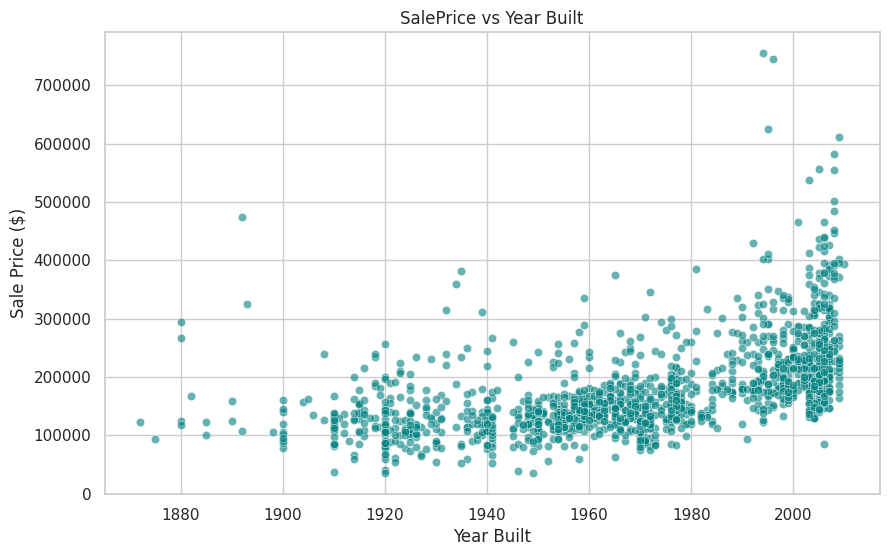

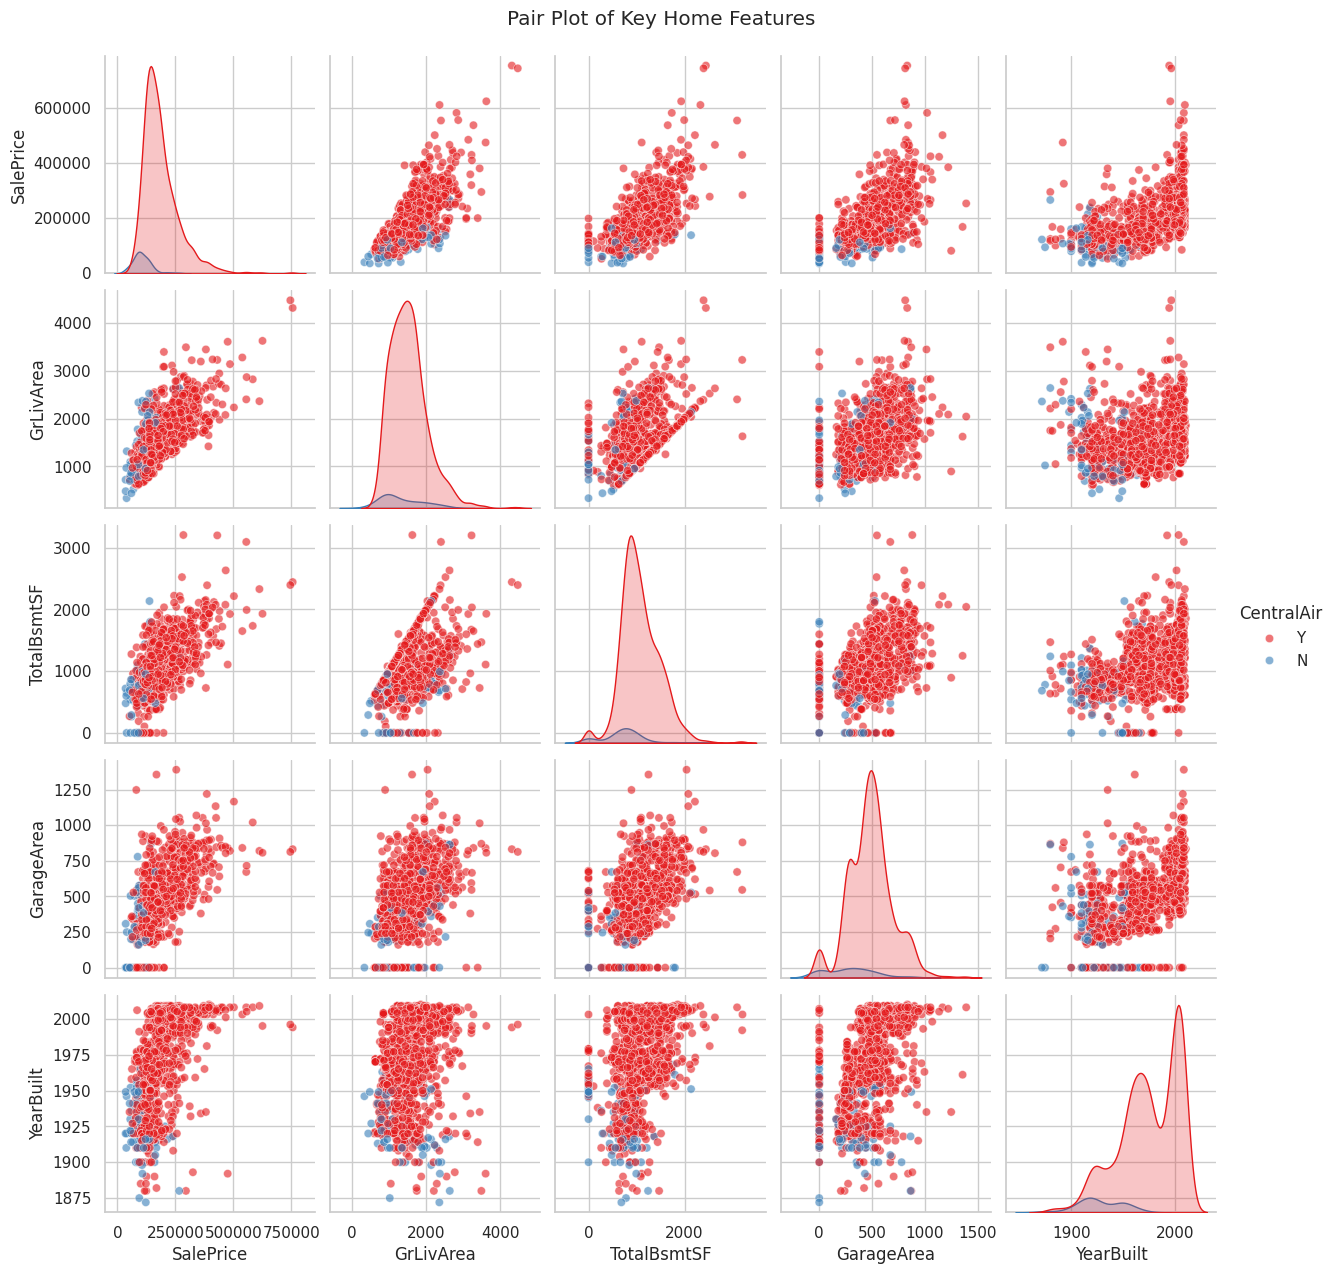

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. SCATTER GrLivArea (x) vs SalePrice (y)
plt.figure(figsize=(10, 6))
# Identify outliers: GrLivArea > 4000 and low price (e.g., < $300,000)
outliers = (df['GrLivArea'] > 4000) & (df['SalePrice'] < 300000)

# Plot normal points
sns.scatterplot(data=df[~outliers], x='GrLivArea', y='SalePrice', color='blue', alpha=0.6, label='Normal data')
# Plot and highlight outliers in red
sns.scatterplot(data=df[outliers], x='GrLivArea', y='SalePrice', color='red', s=100, marker='D', label='Outliers (Large Area, Low Price)')

# Annotate outlier points
for idx, row in df[outliers].iterrows():
    plt.annotate(f"Outlier (ID {row['Id']})",
                 xy=(row['GrLivArea'], row['SalePrice']),
                 xytext=(row['GrLivArea']-300, row['SalePrice']+40000),
                 arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=6))

plt.title('SalePrice vs Above Ground Living Area (GrLivArea)')
plt.xlabel('Above Ground Living Area (sq ft)')
plt.ylabel('Sale Price ($)')
plt.legend()
plt.show()

# 2. SCATTER TotalBsmtSF vs SalePrice
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='TotalBsmtSF', y='SalePrice', alpha=0.6, color='purple')
plt.title('SalePrice vs Total Basement Square Footage')
plt.xlabel('Total Basement Area (sq ft)')
plt.ylabel('Sale Price ($)')
plt.show()

# 3. SCATTER YearBuilt vs SalePrice
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='YearBuilt', y='SalePrice', alpha=0.6, color='teal')
plt.title('SalePrice vs Year Built')
plt.xlabel('Year Built')
plt.ylabel('Sale Price ($)')
plt.show()

# 4. PAIRPLOT of selected features, diagonal as KDE, colored by CentralAir
selected_features = ['SalePrice', 'GrLivArea', 'TotalBsmtSF', 'GarageArea', 'YearBuilt']
if 'CentralAir' in df.columns:
    # CentralAir provides a useful binary grouping for the pairplot coloring
    sns.pairplot(df[selected_features + ['CentralAir']], hue='CentralAir', diag_kind='kde', palette='Set1', plot_kws={'alpha': 0.6})
else:
    sns.pairplot(df[selected_features], diag_kind='kde', plot_kws={'alpha': 0.6})
plt.suptitle('Pair Plot of Key Home Features', y=1.02)
plt.show()

Step 7: Correlation Heatmap

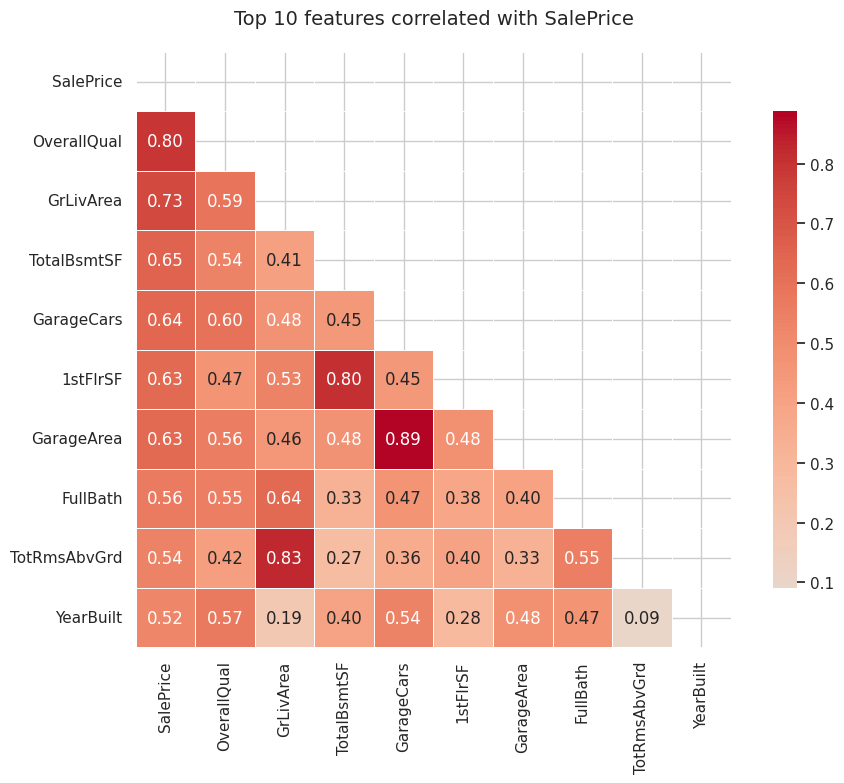

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Identify the 10 numeric features most correlated with SalePrice
numeric_df = df.select_dtypes(include=[np.number])
if 'SalePrice' in numeric_df.columns:
    # Calculate correlation with SalePrice, take absolute values, and sort
    top10_corr = numeric_df.corr()['SalePrice'].abs().sort_values(ascending=False).head(10)
    top10_features = top10_corr.index.tolist()

    # 2. Compute correlation matrix for these top 10 features
    corr_top = df[top10_features].corr()

    # 3. Create a mask for the upper triangle (to hide duplicate half)
    mask = np.triu(np.ones_like(corr_top, dtype=bool))

    # 4. Generate the heatmap
    plt.figure(figsize=(10, 8))
    sns.heatmap(
        corr_top,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        mask=mask,
        square=True,
        linewidths=0.5,
        cbar_kws={"shrink": 0.8}
    )

    # Set title
    plt.title("Top 10 features correlated with SalePrice", fontsize=14, pad=20)
    plt.tight_layout()
    plt.show()
else:
    print("Error: 'SalePrice' column not found in the dataframe.")

Step 8: Outlier Detection

--- Outlier Analysis for GrLivArea ---
IQR method count:      31
Z-score method count:  16
Overlap (both methods): 16

--- Outlier Analysis for SalePrice ---
IQR method count:      61
Z-score method count:  22
Overlap (both methods): 22



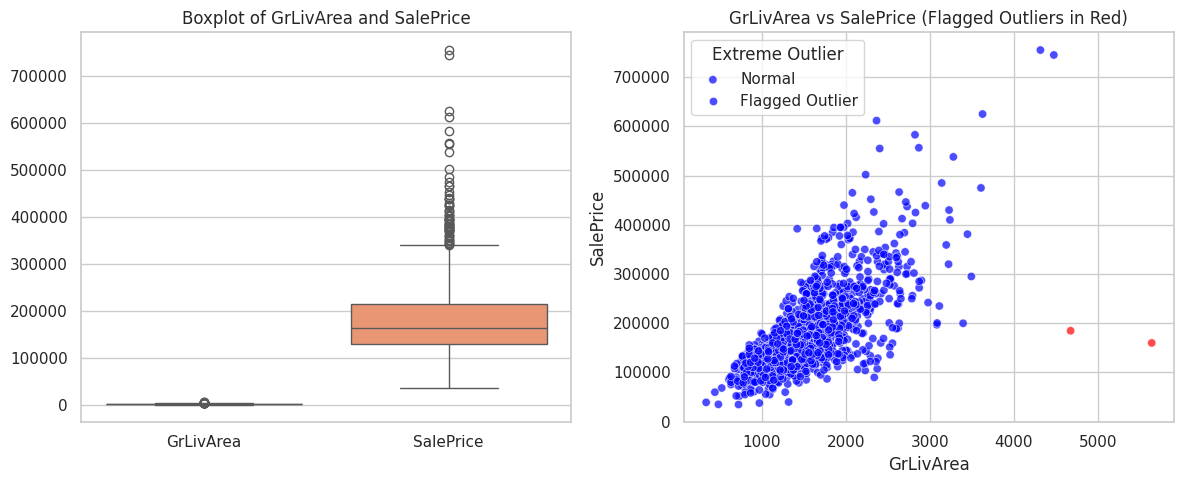

Decision: Removing extreme outliers (GrLivArea > 4000 and SalePrice < 300000) because they represent non-typical sales.
Dataframe cleaned. Shape changed from (1460, 81) to (1458, 81).


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return series[(series < lower) | (series > upper)]

def zscore_outliers(series, threshold=3):
    mean_val = series.mean()
    std_val = series.std()
    z_scores = (series - mean_val) / std_val
    return series[z_scores.abs() > threshold]

# Analyze outliers for target columns
targets = ['GrLivArea', 'SalePrice']

for col in targets:
    if col in df.columns:
        a_outliers = iqr_outliers(df[col])
        b_outliers = zscore_outliers(df[col])

        # Overlap
        overlap = set(a_outliers.index).intersection(set(b_outliers.index))

        print(f"--- Outlier Analysis for {col} ---")
        print(f"IQR method count:      {len(a_outliers)}")
        print(f"Z-score method count:  {len(b_outliers)}")
        print(f"Overlap (both methods): {len(overlap)}\n")

# Visualize outliers on a Boxplot
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.boxplot(data=df[targets], palette="Set2")
plt.title("Boxplot of GrLivArea and SalePrice")

# Visualize flagged points on Scatterplot
plt.subplot(1, 2, 2)
# Flag extreme outliers (classic Ames dataset outliers)
extreme_outliers = (df['GrLivArea'] > 4000) & (df['SalePrice'] < 300000)
sns.scatterplot(data=df, x='GrLivArea', y='SalePrice', hue=extreme_outliers, palette={False: 'blue', True: 'red'}, alpha=0.7)
plt.title("GrLivArea vs SalePrice (Flagged Outliers in Red)")
plt.xlabel("GrLivArea")
plt.ylabel("SalePrice")
plt.legend(title="Extreme Outlier", labels=["Normal", "Flagged Outlier"])
plt.tight_layout()
plt.show()

# Decision and cleaning
print("Decision: Removing extreme outliers (GrLivArea > 4000 and SalePrice < 300000) because they represent non-typical sales.")
initial_shape = df.shape
df = df[~extreme_outliers].reset_index(drop=True)
print(f"Dataframe cleaned. Shape changed from {initial_shape} to {df.shape}.")

 Step 9: Data Quality Checks

In [14]:
import pandas as pd
import numpy as np

# 1. Duplicated rows check
dup_count = df.duplicated().sum()
print(f"Duplicated rows count: {dup_count}")
if dup_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Removed duplicates. New shape: {df.shape}")
print("-" * 50)

# 2. Standardize categorical columns (whitespace strip & casing checks)
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
for col in categorical_cols:
    if df[col].dtype.name != 'category':
        # Strip leading/trailing whitespaces
        df[col] = df[col].astype(str).str.strip()
        # Replace "nan" string back to actual NaN values
        df[col] = df[col].replace('nan', np.nan)

# 3. Handle specific missing categorical features (where NA means 'None')
none_fill_cols = ["PoolQC", "Alley", "Fence", "FireplaceQu", "GarageType", "GarageFinish", "GarageQual", "GarageCond", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]
for col in none_fill_cols:
    if col in df.columns:
        if df[col].dtype.name == 'category':
            # If it is a categorical type, we must add 'None' to categories first
            if 'None' not in df[col].cat.categories:
                df[col] = df[col].cat.add_categories('None')
        df[col] = df[col].fillna('None')

# 4. Fill numeric missing values (LotFrontage grouped by Neighborhood median, others with overall median)
numeric_cols_with_nan = df.select_dtypes(include=[np.number]).columns[df.select_dtypes(include=[np.number]).isnull().any()].tolist()

if 'LotFrontage' in numeric_cols_with_nan:
    # Fill LotFrontage by Neighborhood median
    df['LotFrontage'] = df.groupby('Neighborhood')['LotFrontage'].transform(lambda x: x.fillna(x.median()))
    numeric_cols_with_nan.remove('LotFrontage')

# Fill any remaining numeric missing columns with their column median
for col in numeric_cols_with_nan:
    df[col] = df[col].fillna(df[col].median())

# Fill remaining categorical missing values with "None" or mode
remaining_nan_cats = df.select_dtypes(include=['object', 'category']).columns[df.select_dtypes(include=['object', 'category']).isnull().any()]
for col in remaining_nan_cats:
    mode_val = df[col].mode()
    fill_val = mode_val.iloc[0] if not mode_val.empty else "None"
    if df[col].dtype.name == 'category' and fill_val not in df[col].cat.categories:
        df[col] = df[col].cat.add_categories(fill_val)
    df[col] = df[col].fillna(fill_val)

# 5. Verify remaining missing counts
remaining_missing = df.isnull().sum().sum()
print(f"Remaining missing values in dataframe: {remaining_missing}")
print("-" * 50)

# 6. Check impossible values
print("--- Logical Consistency Checks ---")
impossible_years = df[df['YearBuilt'] > df['YrSold']]
print(f"Rows where YearBuilt > YrSold: {len(impossible_years)}")

negative_areas = df[(df['LotArea'] < 0) | (df['GrLivArea'] < 0) | (df['TotalBsmtSF'] < 0)]
print(f"Rows with negative area values: {len(negative_areas)}")

Duplicated rows count: 0
--------------------------------------------------
Remaining missing values in dataframe: 0
--------------------------------------------------
--- Logical Consistency Checks ---
Rows where YearBuilt > YrSold: 0
Rows with negative area values: 0


Step 10: Final Dashboard and Storytelling

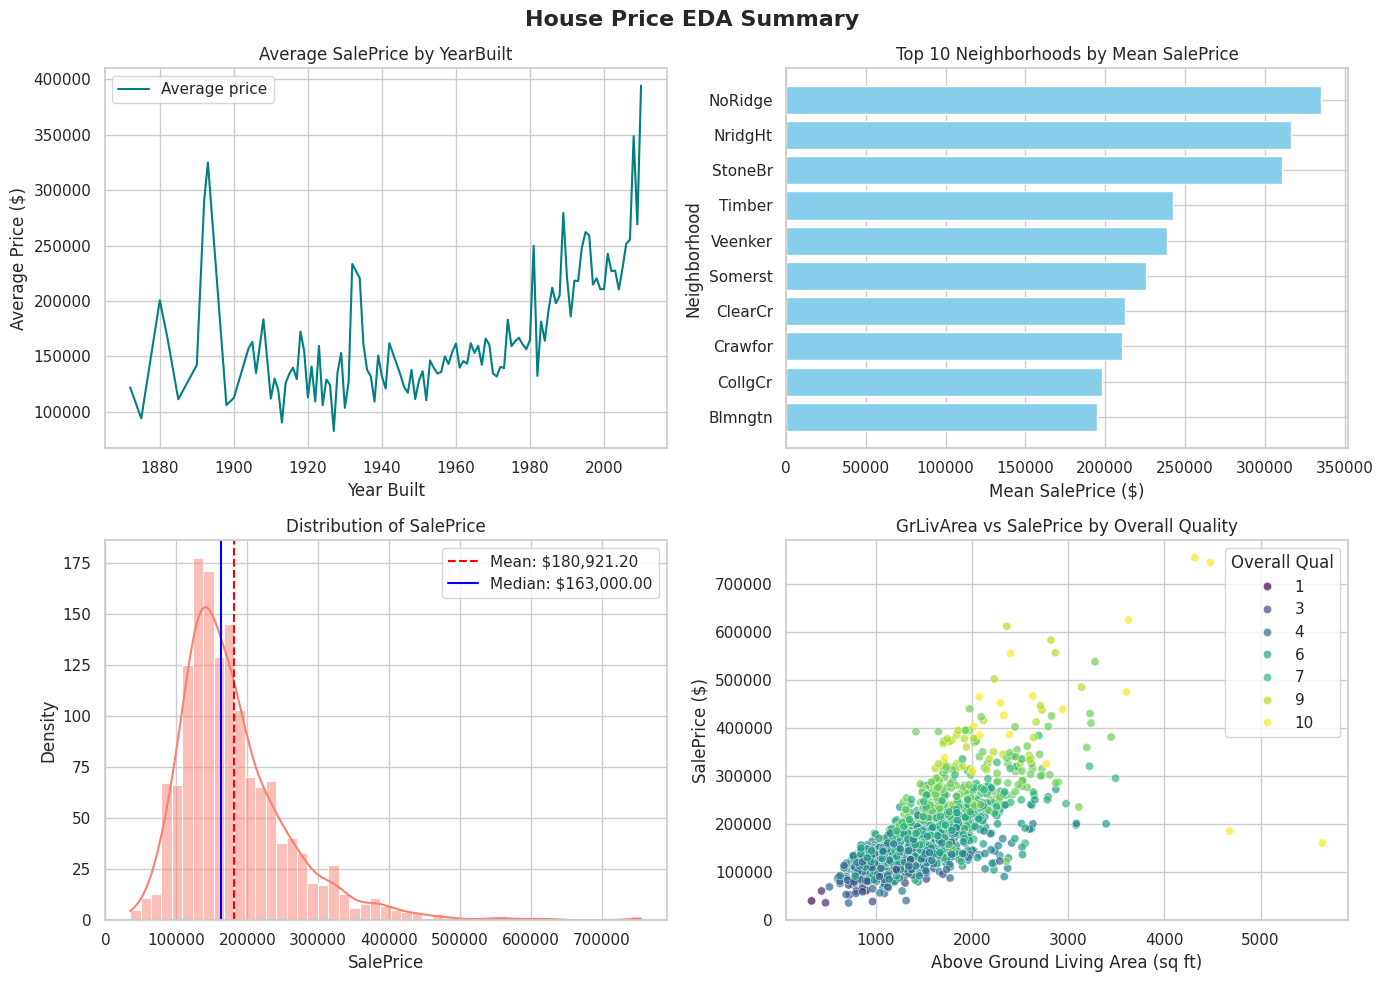

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Create a figure with 2 rows x 2 columns
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Panel 1 (Matplotlib line plot): Group df by YearBuilt, compute mean SalePrice
year_built_prices = df.groupby('YearBuilt')['SalePrice'].mean().reset_index()
axes[0, 0].plot(year_built_prices['YearBuilt'], year_built_prices['SalePrice'], color='teal', label='Average price')
axes[0, 0].set_title('Average SalePrice by YearBuilt')
axes[0, 0].set_xlabel('Year Built')
axes[0, 0].set_ylabel('Average Price ($)')
axes[0, 0].legend()

# Panel 2 (Matplotlib bar plot): Group by Neighborhood, mean SalePrice, take top 10
top_neighborhoods = df.groupby('Neighborhood')['SalePrice'].mean().sort_values(ascending=False).head(10).reset_index()
axes[0, 1].barh(top_neighborhoods['Neighborhood'], top_neighborhoods['SalePrice'], color='skyblue')
axes[0, 1].invert_yaxis()  # Put highest value at the top
axes[0, 1].set_title('Top 10 Neighborhoods by Mean SalePrice')
axes[0, 1].set_xlabel('Mean SalePrice ($)')
axes[0, 1].set_ylabel('Neighborhood')

# Panel 3 (Seaborn histplot with KDE): SalePrice distribution, mark mean and median
sns.histplot(df['SalePrice'], kde=True, ax=axes[1, 0], color='salmon')
mean_price = df['SalePrice'].mean()
median_price = df['SalePrice'].median()
axes[1, 0].axvline(mean_price, color='red', linestyle='--', label=f'Mean: ${mean_price:,.2f}')
axes[1, 0].axvline(median_price, color='blue', linestyle='-', label=f'Median: ${median_price:,.2f}')
axes[1, 0].set_title('Distribution of SalePrice')
axes[1, 0].set_xlabel('SalePrice')
axes[1, 0].set_ylabel('Density')
axes[1, 0].legend()

# Panel 4 (Seaborn scatter): GrLivArea vs SalePrice colored by OverallQual
sns.scatterplot(data=df, x='GrLivArea', y='SalePrice', hue='OverallQual', palette='viridis', ax=axes[1, 1], alpha=0.7)
axes[1, 1].set_title('GrLivArea vs SalePrice by Overall Quality')
axes[1, 1].set_xlabel('Above Ground Living Area (sq ft)')
axes[1, 1].set_ylabel('SalePrice ($)')
axes[1, 1].legend(title='Overall Qual')

# Set final layout and global dashboard title
plt.suptitle('House Price EDA Summary', fontsize=16, weight='bold', y=0.98)
plt.tight_layout()

# Save figure
plt.savefig("eda_dashboard.png", dpi=300)
plt.show()